# ResNet101 Reproduction: Defect Detection in 3D-Printed Objects

Reproduction of the paper: *Defect analysis of 3D printed object using transfer learning approaches*
(Ahsan et al., Expert Systems with Applications, 2024)
https://doi.org/10.1016/j.eswa.2024.124293

**Method**: ImageNet-pretrained ResNet101 with all convolutional layers frozen;
only the new classification head (GAP -> Dense(256) -> Dropout -> sigmoid) is trained,
using the Adam optimizer for 30 epochs.

**Data** (two studies, matching the paper):
- Study One (small, balanced): `dataset` -> badcylinder (defect) + goodcylinder (non-defect), 271 images in total
- Study Two (large, imbalanced): `Augmented_data` -> Badaug + Goodaug, 3017 images in total
- Study Three (temporal extrapolation): `dataset` split by capture time (filename order) --
  train on early photos, test on later ones, to expose near-duplicate leakage of random splits


In [1]:
# ===== Step 1: Import libraries =====
import os, random
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet101
from tensorflow.keras.applications.resnet import preprocess_input

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, auc,
                             matthews_corrcoef, cohen_kappa_score)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.22.0-rc1


## Step 2: Configuration

Update the paths below to match your machine (on Windows, use raw strings `r"..."` or forward slashes `/`).

In [2]:
# ===== Step 2: Paths and hyperparameters =====
# --- Data paths (change to your local paths) ---
DATA_ROOT = r"D:\Desktop\7215\group work\AMdataset-main\AMdataset-main"  # repository root
STUDY_ONE = os.path.join(DATA_ROOT, "dataset")         # Study One: 136 + 135 images
STUDY_TWO = os.path.join(DATA_ROOT, "Augmented_data")  # Study Two: 947 + 2070 images

# --- Select the experiment: "one" / "two" (random split) or "three" (time-based split) ---
STUDY_THREE = os.path.join(DATA_ROOT, "dataset")       # Study Three: raw photos, temporal split
STUDY = "one"
if STUDY == "one":
    DATA_DIR, STUDY_NAME = STUDY_ONE, "study_one"
elif STUDY == "two":
    DATA_DIR, STUDY_NAME = STUDY_TWO, "study_two"
else:
    DATA_DIR, STUDY_NAME = STUDY_THREE, "study_three"

# --- Hyperparameters (aligned with the paper / reference repo) ---
SEED          = 42
EPOCHS        = 15
BATCH_SIZE    = 30
IMG_SIZE      = (224, 224)
OPTIMIZER     = "adam"    # paper ablation: Adam / RMSprop clearly outperform SGD; try "rmsprop" / "sgd"
LEARNING_RATE = 1e-4

# --- Output directory ---
OUT_DIR = f"results_{STUDY_NAME}"
os.makedirs(OUT_DIR, exist_ok=True)

print("Current study :", STUDY_NAME)
print("Data directory:", DATA_DIR)
print("Output dir    :", OUT_DIR)


Current study : study_one
Data directory: D:\Desktop\7215\group work\AMdataset-main\AMdataset-main\dataset
Output dir    : results_study_one


## Step 3: Data inspection

Class labels are encoded alphabetically from the folder names: **badcylinder = 0 (defect)**, **goodcylinder = 1 (non-defect)**.

In [3]:
# ===== Step 3: Count images per class =====
import glob

class_dirs = sorted(d for d in os.listdir(DATA_DIR)
                    if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Class folders (alphabetical order = label order):")
total = 0
for idx, c in enumerate(class_dirs):
    n = len(glob.glob(os.path.join(DATA_DIR, c, "*.*")))
    total += n
    print(f"  label {idx} - {c}: {n} images")
print("Total:", total, "images")


Class folders (alphabetical order = label order):
  label 0 - badcylinder: 136 images
  label 1 - goodcylinder: 135 images
Total: 271 images


## Step 4: Load datasets (70% train / 15% val / 15% test)

`image_dataset_from_directory` handles the split automatically; ResNet-style ImageNet
preprocessing (including /255) is applied via `preprocess_input`.

In [4]:
# ===== Step 4: Load and split the dataset =====
# Studies one/two: stratified RANDOM 70/15/15 split (seed 42).
# Study three: TEMPORAL split - files sorted by filename (capture-time order for
# the time-lapse photos); first 70% train, middle 15% val, last 15% test.
# No shuffling is applied BEFORE the split in either mode.
def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)

set_seed(SEED)

# --- Collect file paths and labels ---
class_names = sorted(d for d in os.listdir(DATA_DIR)
                     if os.path.isdir(os.path.join(DATA_DIR, d)))

splits = {"train": [[], []], "val": [[], []], "test": [[], []]}
for idx, c in enumerate(class_names):   # label 0 = badcylinder (defect), 1 = goodcylinder
    files = sorted(glob.glob(os.path.join(DATA_DIR, c, "*.*")))
    n_train = int(0.70 * len(files))
    n_val = int(0.15 * len(files))
    if STUDY in ("one", "two"):
        rng = np.random.RandomState(SEED)
        rng.shuffle(files)   # random split: shuffle first, then slice
    # else (study three): keep filename (= capture time) order for extrapolation
    for name, part in zip(("train", "val", "test"),
                          (files[:n_train], files[n_train:n_train + n_val], files[n_train + n_val:])):
        splits[name][0] += part
        splits[name][1] += [idx] * len(part)

# --- Save split manifests (auditable: which file went where) ---
for name in ("train", "val", "test"):
    pd.DataFrame({"path": splits[name][0], "label": splits[name][1]}).to_csv(
        os.path.join(OUT_DIR, f"split_{name}.csv"), index=False)

# --- Build tf.data pipelines from the file lists ---
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return preprocess_input(img), label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(1000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(*splits["train"], training=True)
val_ds   = make_dataset(*splits["val"])
test_ds  = make_dataset(*splits["test"])

for name in ("train", "val", "test"):
    print(name, "images:", len(splits[name][0]),
          "| defects:", splits[name][1].count(0),
          "| non-defects:", splits[name][1].count(1))
print(f"train batches: {len(train_ds)}  val batches: {len(val_ds)}  test batches: {len(test_ds)}")


train images: 189 | defects: 95 | non-defects: 94
val images: 40 | defects: 20 | non-defects: 20
test images: 42 | defects: 21 | non-defects: 21
train batches: 7  val batches: 2  test batches: 2


## Step 5: Visualize training samples (sanity check)

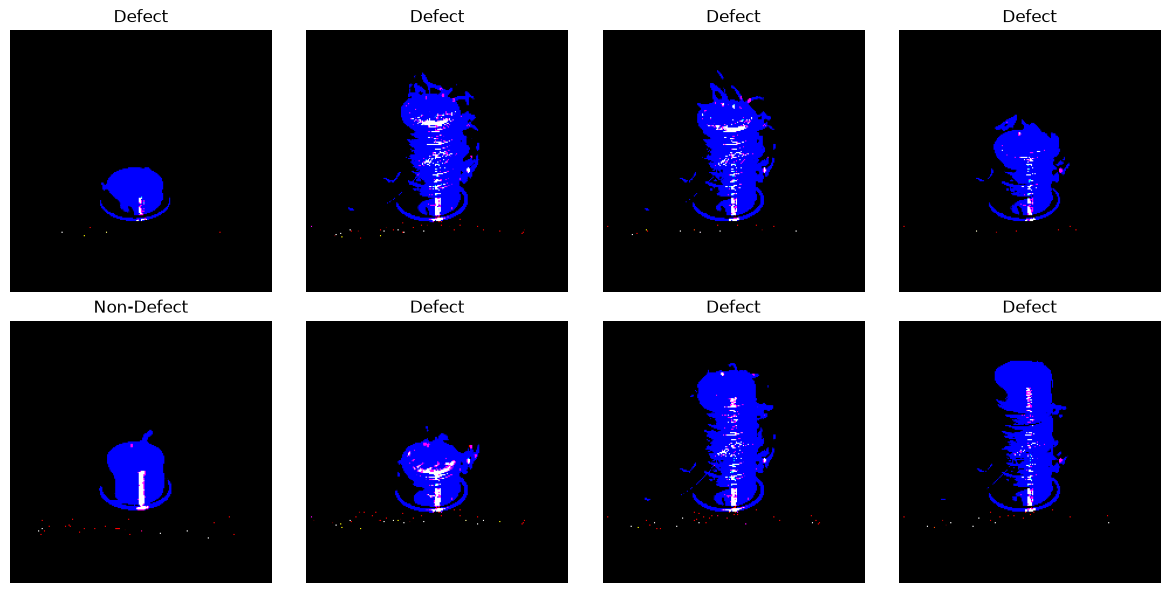

In [5]:
# ===== Step 5: Show 8 training samples =====
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i, ax in enumerate(axes.flat):
        img = images[i].numpy()
        # Invert the ResNet preprocessing for display (mean/std normalization)
        img = img * np.array([58.393, 57.12, 57.375]) + np.array([123.675, 116.779, 103.939])
        img = np.clip(img / 255.0, 0, 1)
        ax.imshow(img)
        ax.set_title("Defect" if labels[i].numpy() < 0.5 else "Non-Defect")
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sample_images.png"), dpi=150)
plt.show()


## Step 6: Build the model (frozen ResNet101 + new classification head)

Identical to the paper's flow diagram: all pretrained convolutional layers are frozen;
only GAP -> Dense -> Dropout -> FC output layers are trained.

In [6]:
# ===== Step 6: Build the model =====
base = ResNet101(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
base.trainable = False   # paper setting: freeze pretrained weights

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)          # Average Pooling
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation="relu")(x)     # updated Dense layer
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)  # FC output layer

model = keras.Model(inputs, outputs)

opts = {"adam": keras.optimizers.Adam(LEARNING_RATE),
        "sgd": keras.optimizers.SGD(LEARNING_RATE, momentum=0.9),
        "rmsprop": keras.optimizers.RMSprop(LEARNING_RATE)}
model.compile(optimizer=opts[OPTIMIZER], loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet101 (Functional)               │ (None, 7, 7, 2048)          │      42,658,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 2048)                │           8,192 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 43,191,169 (164.76 MB)

 Trainable params: 528,897 (2.02 MB)

 Non-trainable params: 42,662,272 (162.74 MB)

## Step 7: Training

EarlyStopping (patience 8) and learning-rate reduction on plateau;
the best model is saved automatically to the output directory.

In [7]:
# ===== Step 7: Train =====
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=4, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint(os.path.join(OUT_DIR, "resnet101_best.keras"),
                                    monitor="val_loss", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=EPOCHS, callbacks=callbacks,
                    shuffle=False)  # shuffling is handled in the Dataset pipeline (see Step 4)

model.save(os.path.join(OUT_DIR, "resnet101_final.keras"))
print("Model saved to:", OUT_DIR)


Epoch 1/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 109s 12s/step - accuracy: 0.5450 - loss: 0.6666 - val_accuracy: 0.8750 - val_loss: 0.2870 - learning_rate: 1.0000e-04
Epoch 2/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 38s 5s/step - accuracy: 0.9365 - loss: 0.2479 - val_accuracy: 1.0000 - val_loss: 0.0996 - learning_rate: 1.0000e-04
Epoch 3/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 0.9577 - loss: 0.1312 - val_accuracy: 1.0000 - val_loss: 0.0734 - learning_rate: 1.0000e-04
Epoch 4/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 1.0000 - loss: 0.0848 - val_accuracy: 1.0000 - val_loss: 0.0674 - learning_rate: 1.0000e-04
Epoch 5/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 1.0000 - loss: 0.0608 - val_accuracy: 1.0000 - val_loss: 0.0358 - learning_rate: 1.0000e-04
Epoch 6/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 5s/step - accuracy: 1.0000 - loss: 0.0429 - val_accuracy: 1.0000 - val_loss: 0.0233 - learning_rate: 1.0000e-04
Epoch 7/15
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 5s/step - accuracy: 1.0000 - loss: 0.0338 - va

## Step 8: Plot training curves

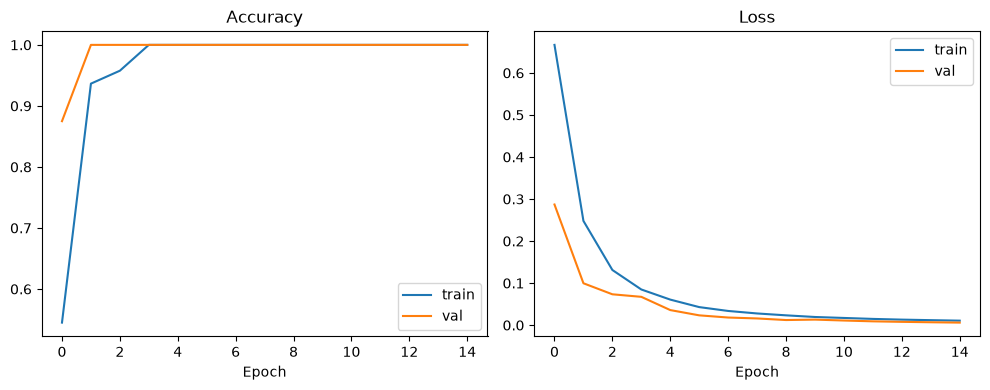

In [8]:
# ===== Step 8: Training curves =====
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "training_history.png"), dpi=150)
plt.show()


## Step 9: Test-set evaluation (all metrics used in the paper)

Reports Accuracy / Precision / Recall / F1 / MCC / Kappa / AUC,
plus the confusion matrix and ROC curve.

========== Test results ==========
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1        : 1.0000
Mcc       : 1.0000
Kappa     : 1.0000
Auc       : 1.0000

Confusion matrix (rows=true, cols=pred; label 0=Defect, 1=Non-Defect):
[[21  0]
 [ 0 21]]


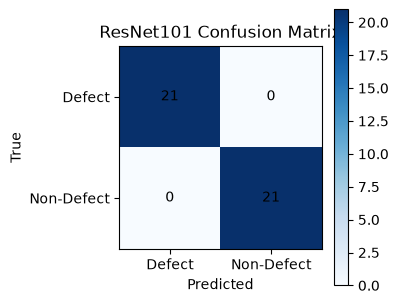

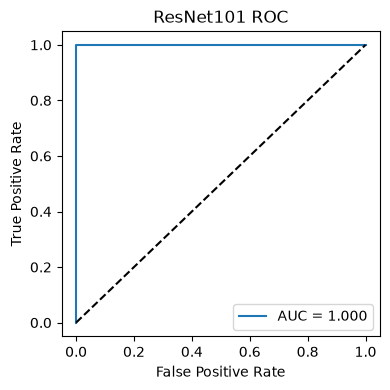

In [12]:
# ===== Step 9: Test-set evaluation =====
y_true, y_prob = [], []
for images, labels in test_ds.unbatch().batch(64):
    y_prob.extend(model.predict(images, verbose=0).ravel().tolist())
    y_true.extend(labels.numpy().ravel().tolist())

y_prob = np.array(y_prob)
y_true = np.array(y_true).astype(int)
# y_prob is P(label=1). Predict defect (label 0) when P(label=1) < 0.5
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "accuracy":  accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall":    recall_score(y_true, y_pred, zero_division=0),
    "f1":        f1_score(y_true, y_pred, zero_division=0),
    "mcc":       matthews_corrcoef(y_true, y_pred),
    "kappa":     cohen_kappa_score(y_true, y_pred),
}
# ROC: positive class is defect (label 0), so use P(defect) = 1 - y_prob
fpr, tpr, _ = roc_curve(y_true,  y_prob)
metrics["auc"] = auc(fpr, tpr)

print("========== Test results ==========")
for k, v in metrics.items():
    print(f"{k.capitalize():10s}: {v:.4f}")

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion matrix (rows=true, cols=pred; label 0=Defect, 1=Non-Defect):")
print(cm)

fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Defect", "Non-Defect"]); ax.set_yticklabels(["Defect", "Non-Defect"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("ResNet101 Confusion Matrix")
for r in range(cm.shape[0]):
    for c in range(cm.shape[1]):
        ax.text(c, r, cm[r, c], ha="center", va="center")
fig.colorbar(im); fig.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(fpr, tpr, label=f"AUC = {metrics['auc']:.3f}")
ax.plot([0, 1], [0, 1], "k--")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ResNet101 ROC"); ax.legend(); fig.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "roc_curve.png"), dpi=150)
plt.show()


## Step 10: Save per-image predictions (auditable evidence, following the reference repo)

In [10]:
# ===== Step 10: Per-image prediction CSV =====
df = pd.DataFrame({"image_index": range(len(y_true)),
                   "y_true": y_true,
                   "y_prob_defect": 1 - y_prob,   # P(defect) = 1 - P(label=1)
                   "y_pred": y_pred})
df.to_csv(os.path.join(OUT_DIR, "per_image_predictions.csv"), index=False)
print("Saved:", os.path.join(OUT_DIR, "per_image_predictions.csv"))
df.head()


Saved: results_study_one\per_image_predictions.csv


,image_index,y_true,y_prob_defect,y_pred
0,0,0,0.867710,1
1,1,0,0.999833,1
2,2,0,0.986886,1
3,3,0,0.849301,1
4,4,0,0.995732,1


## Step 11: Save a summary of this run

In [11]:
# ===== Step 11: Save metrics summary =====
metrics.update({"study": STUDY_NAME, "optimizer": OPTIMIZER, "seed": SEED,
                "epochs": EPOCHS, "batch_size": BATCH_SIZE})
pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
print("All results saved in:", OUT_DIR)
print(os.listdir(OUT_DIR))


All results saved in: results_study_one
['confusion_matrix.png', 'metrics.csv', 'per_image_predictions.csv', 'resnet101_best.keras', 'resnet101_final.keras', 'roc_curve.png', 'sample_images.png', 'training_history.png']
